# Model Training

Objetivos:
- carregar e pré-processar o dataset
- split treino/test
- treinar Logistic Regression, Decision Tree, Random Forest
- avaliar com accuracy, precision, recall, F1, ROC-AUC
- comparar resultados e guardar modelos/metrics

In [30]:
# Imports
import pandas as pd
import numpy as np
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import joblib

sns.set_style('whitegrid')

## Load dataset 


In [ ]:
data_path = Path("../data/students_dataset.csv")
df = pd.read_csv(data_path)
df.shape

(1000, 9)

## Preprocessing
- separar X/y
- opcionais: scaling para modelos lineares
- nota: vamos usar `stratify` no split devido ao desbalanceamento

In [32]:
# Select features and target
X = df.drop(columns=['student_id','at_risk'])
y = df['at_risk']
print('Features:', X.shape)
print('Target:', y.shape)

Features: (1000, 7)
Target: (1000,)


## Train/test split and baseline model (Logistic Regression)

In [33]:
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print('Train size:', X_train.shape)
print('Test size:', X_test.shape)

# Scale only for Logistic Regression to avoid data leakage
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

# Logistic Regression baseline
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)
y_proba_lr = lr.predict_proba(X_test_scaled)[:,1]

print('LR accuracy:', accuracy_score(y_test, y_pred_lr))
print('LR precision:', precision_score(y_test, y_pred_lr))
print('LR recall:', recall_score(y_test, y_pred_lr))
print('LR f1:', f1_score(y_test, y_pred_lr))
print('LR roc_auc:', roc_auc_score(y_test, y_proba_lr))

Train size: (800, 7)
Test size: (200, 7)
LR accuracy: 0.835
LR precision: 0.7547169811320755
LR recall: 0.6666666666666666
LR f1: 0.7079646017699115
LR roc_auc: 0.909047619047619


## Train Decision Tree and Random Forest

In [34]:
# Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print('DT f1:', f1_score(y_test, y_pred_dt))
print('RF f1:', f1_score(y_test, y_pred_rf))

DT f1: 0.6166666666666667
RF f1: 0.6666666666666666


## Evaluation and comparison

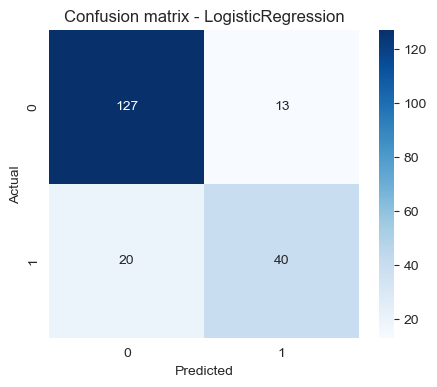

Saved metrics, scaler, models, and best-model bundle to ..\results


In [37]:
models = {'LogisticRegression': (lr, y_pred_lr, X_test_scaled), 'DecisionTree': (dt, y_pred_dt, X_test), 'RandomForest': (rf, y_pred_rf, X_test)}

rows = []
for name, (model, y_pred, X_eval) in models.items():
    proba = model.predict_proba(X_eval)[:,1] if hasattr(model, 'predict_proba') else None
    rows.append({
        'model': name,
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'roc_auc': roc_auc_score(y_test, proba) if proba is not None else None
    })

metrics_df = pd.DataFrame(rows).set_index('model')
metrics_df

# Confusion matrix for best model (by f1)
best = metrics_df['f1'].idxmax()
best_model = models[best][0]
best_eval_features = models[best][2]
cm = confusion_matrix(y_test, best_model.predict(best_eval_features))
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion matrix - {best}')
plt.show()

# Ensure output directory exists and save metrics and models
out_dir = Path('..') / 'results'
out_dir.mkdir(parents=True, exist_ok=True)
metrics_df.to_csv(out_dir / 'model_metrics.csv')
joblib.dump(scaler, out_dir / 'scaler.joblib')
for name, (model, _, _) in models.items():
    joblib.dump(model, out_dir / f'{name}.joblib')

# Save the best model bundle for the web app
best_model_name = metrics_df['f1'].idxmax()
best_model_obj = models[best_model_name][0]
best_model_bundle = {
    'model_name': best_model_name,
    'model': best_model_obj,
    'scaler': scaler if best_model_name == 'LogisticRegression' else None,
    'feature_names': list(X.columns)
}
joblib.dump(best_model_bundle, Path('..') / 'models' / 'student_risk_model.joblib')

print(f'Saved metrics, scaler, models, and best-model bundle to {out_dir}')

## Feature importance and model comparison table

Top features by Random Forest importance:
          feature  random_forest_importance
study_time_weekly                  0.371189
         absences                  0.187894
      sleep_hours                  0.186159
     stress_level                  0.109434
 parental_support                  0.069902


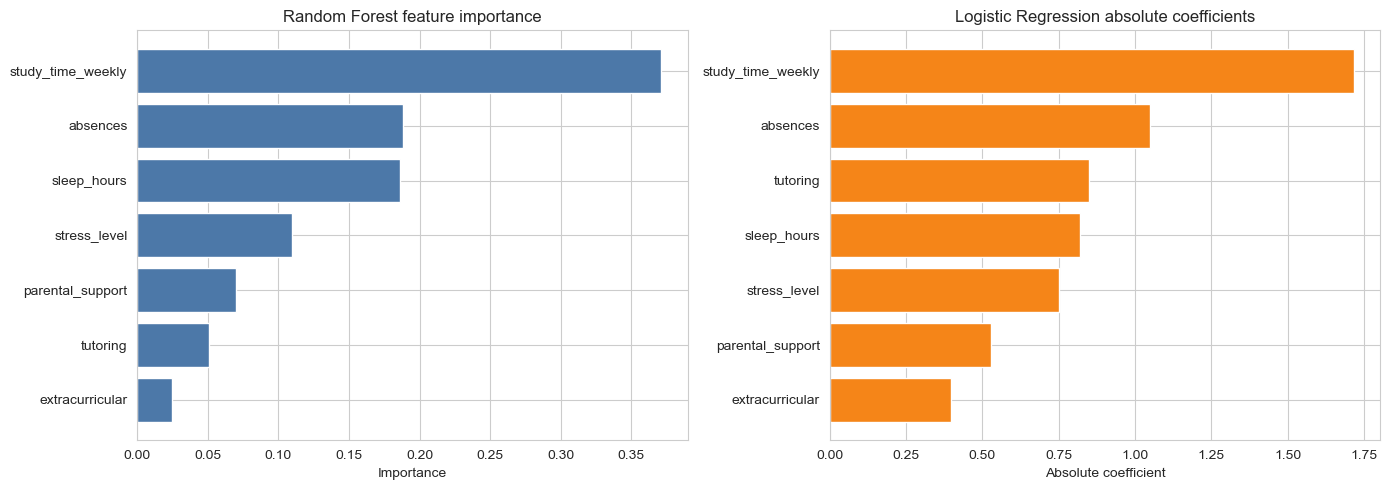

Best model by F1: LogisticRegression


In [36]:
# Comparison table sorted by F1 score
comparison_df = metrics_df.sort_values(['f1', 'recall', 'roc_auc'], ascending=False)
comparison_df

# Feature importance from the trained models
feature_importance_df = pd.DataFrame({
    'feature': X.columns,
    'random_forest_importance': rf.feature_importances_,
    'logistic_regression_abs_coef': np.abs(lr.coef_[0])
}).sort_values('random_forest_importance', ascending=False)

print('Top features by Random Forest importance:')
print(feature_importance_df[['feature', 'random_forest_importance']].head(5).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rf_top = feature_importance_df.head(7).sort_values('random_forest_importance')
axes[0].barh(rf_top['feature'], rf_top['random_forest_importance'], color='#4C78A8')
axes[0].set_title('Random Forest feature importance')
axes[0].set_xlabel('Importance')

lr_top = feature_importance_df.sort_values('logistic_regression_abs_coef', ascending=False).head(7).sort_values('logistic_regression_abs_coef')
axes[1].barh(lr_top['feature'], lr_top['logistic_regression_abs_coef'], color='#F58518')
axes[1].set_title('Logistic Regression absolute coefficients')
axes[1].set_xlabel('Absolute coefficient')

plt.tight_layout()
plt.show()

print('Best model by F1:', comparison_df.index[0])